# 🧱 Cell 1: 环境配置与路径定义 🛠️

# 首先导入所有必要的库，并定义好你的数据集路径。

In [44]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import *
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm

# 路径配置 (请确保这些目录已存在)
RAW_DATA_PATH = r"G:\WSLearning\Data"  # 原始图像根目录
FEATURE_PATH = r"G:\WSLearning\Data\features"  # 存放提取后的特征文件 (.pt)
MODEL_SAVE_PATH = "best_mil_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前设备: {device} | 显存限制: 16G (请放心使用)")


当前设备: cuda | 显存限制: 16G (请放心使用)


# 🧱 Cell 2: 特征提取（核心：降维至 512 维） 🔍

# 这里我提供了 ResNet50 作为默认骨干，它最稳定。 

# 我们添加了一个 nn.Linear(2048, 512)  来强制降维。

# 运行建议： 这一步最耗时，建议先拿 2-3 个病人试运行。


## Vit的特征提取效果跟好

In [60]:
import os, torch, timm, numpy as np
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from torchvision import transforms

RAW_PATCH_ROOT = r"G:\WSLearning\Data"
SAVE_ROOT = r"G:\WSLearning\Data\features.vit"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        os.makedirs(os.path.join(SAVE_ROOT, s, l), exist_ok=True)

# 加载 ViT（timm 支持 PyTorch 1.12）
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
model.to(DEVICE).eval()
print(f"✅ ViT-Base 加载成功，特征维度: 768")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

def extract(split, label):
    src = Path(RAW_PATCH_ROOT) / split / label
    dst = Path(SAVE_ROOT) / split / label
    
    patient_dirs = [d for d in src.iterdir() if d.is_dir()]
    print(f"\n{split}/{label}: {len(patient_dirs)} 个病人")
    
    for p_dir in tqdm(patient_dirs):
        save_path = dst / f"{p_dir.name}.pt"
        if save_path.exists(): continue
        
        patches = list(p_dir.glob("*.png")) + list(p_dir.glob("*.jpg"))
        if not patches: continue
        
        all_feats, all_coords = [], []
        for i in range(0, len(patches), 32):
            batch_paths = patches[i:i+32]
            imgs, coords = [], []
            for p in batch_paths:
                try:
                    imgs.append(transform(Image.open(p).convert('RGB')))
                    xy = p.stem.split('_')
                    coords.append([int(xy[0]), int(xy[1])])
                except: continue
            if not imgs: continue
            
            with torch.no_grad():
                feats = model(torch.stack(imgs).to(DEVICE)).cpu()
            all_feats.append(feats)
            all_coords.extend(coords)
        
        if all_feats:
            torch.save({
                'feats': torch.cat(all_feats).numpy(),
                'coords': np.array(all_coords),
                'label': 1 if label == "High" else 0
            }, save_path)

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        extract(s, l)

print(f"\n✅ 提取完成！保存至: {SAVE_ROOT}")


'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x0000024C8729D580>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: 6b7d97cf-da7d-4a1d-8149-da387043e58b)')' thrown while requesting HEAD https://huggingface.co/timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x0000024C8729D850>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: e2100a65-33ef-4b13-a7c2-c71a3be46d22)')' thrown while requesting HEAD https:

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

C:\Users\niyuan\.conda\envs\deeppt\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\niyuan\.cache\huggingface\hub\models--timm--vit_base_patch16_224.augreg2_in21k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


✅ ViT-Base 加载成功，特征维度: 768

train/High: 16 个病人


100%|██████████████████████████████████████████████████████████████████████████████████| 16/16 [10:50<00:00, 40.65s/it]



train/Low: 21 个病人


... (2 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████| 15/15 [40:27<00:00, 161.83s/it]



val/Low: 20 个病人


100%|███████████████████████████████████████████████████████████████████████████████| 20/20 [1:08:17<00:00, 204.87s/it]


✅ 提取完成！保存至: G:\WSLearning\Data\features.vit


# ResNet50提取的模型，应该是不如VIT

In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet50'):
        super().__init__()
        if model_name == 'resnet50':
            base = models.resnet50(pretrained=True)
            self.backbone = nn.Sequential(*list(base.children())[:-1])
            in_features = 2048
        # 可选: 'vit_small' 或 'mobilenet_v3' (更省显存)
        
        self.fc = nn.Linear(in_features, 512) # 关键步：降维到 512

    def forward(self, x):
        with torch.no_grad():
            x = self.backbone(x)
            x = x.view(x.size(0), -1)
            return self.fc(x)

def run_extraction():
    extractor = FeatureExtractor().to(device).eval()
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    for split in ['train', 'val']:
        for label, class_val in [('High', 1), ('Low', 0)]:
            src_dir = Path(RAW_DATA_PATH) / split / label
            dst_dir = Path(FEATURE_PATH) / split / label
            dst_dir.mkdir(parents=True, exist_ok=True)

            for patient_path in src_dir.iterdir():
                if not patient_path.is_dir(): continue
                p_id = patient_path.name
                save_file = dst_dir / f"{p_id}.pt"
                if save_file.exists(): continue # 跳过已处理的

                images = list(patient_path.glob("*.png")) + list(patient_path.glob("*.jpg"))
                all_feats, all_coords = [], []

                for i in range(0, len(images), 32): # 16G显存 BatchSize设为32比较稳
                    batch_imgs = torch.stack([transform(Image.open(img).convert('RGB')) for img in images[i:i+32]]).to(device)
                    feats = extractor(batch_imgs).cpu().numpy()
                    all_feats.append(feats)
                    
                    # 解析坐标 (TCGA-A6-2684_..._x18623_y3826)
                    for img_p in images[i:i+32]:
                        parts = img_p.stem.split('_')
                        x = int(parts[-2][1:])
                        y = int(parts[-1][1:])
                        all_coords.append([x, y])
                
                torch.save({'feats': np.concatenate(all_feats), 'coords': np.array(all_coords), 'label': class_val}, save_file)
                print(f"已完成样本: {p_id}, 特征形状: {np.concatenate(all_feats).shape}")

run_extraction() # 取消注释以运行


# Vit + RandomForest将提升模型性能

# 这个方法是⭐⭐⭐⭐ 级别

| 方法            | 难度    | 性能 |
| ------------- | ----- | -- |
| Mean pooling  | ⭐     | 基线 |
| Mean+Max      | ⭐⭐    | 稳定 |
| Mean+Max+Std  | ⭐⭐⭐   | 很好 |
| Top-K + 统计    | ⭐⭐⭐⭐  | 很强 |
| Attention MIL | ⭐⭐⭐⭐⭐ | 最强 |


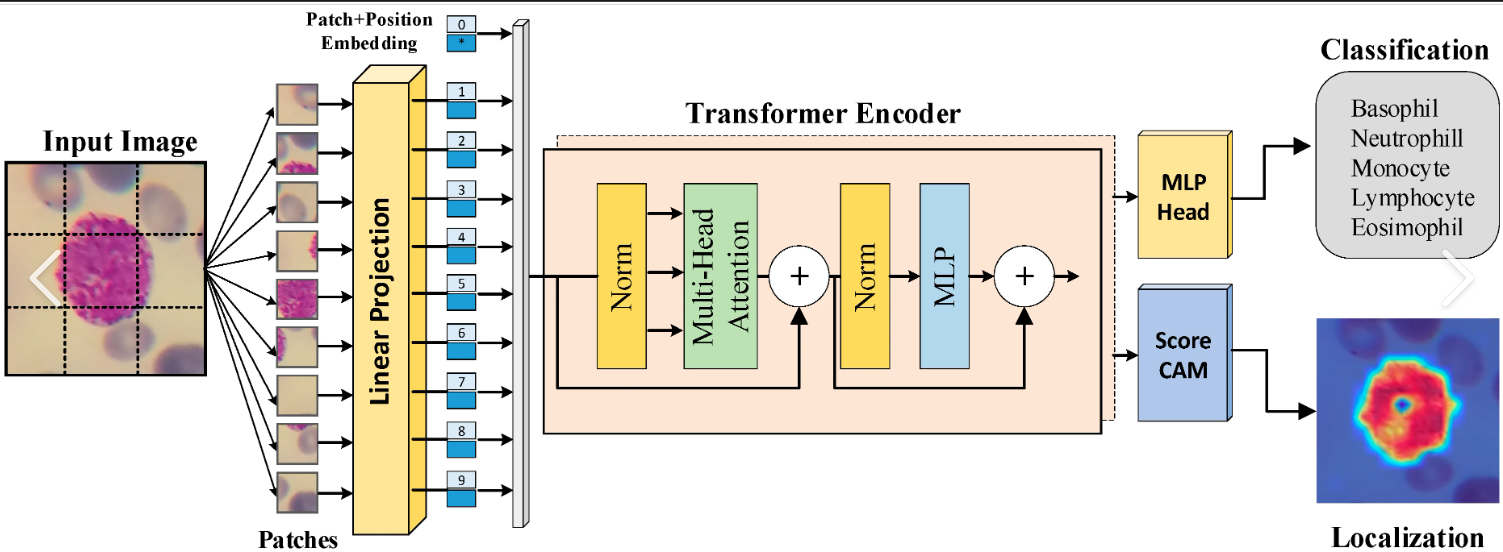

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
from pathlib import Path


def load_topk_features(feature_root, k=20):
    """
    加载所有 .pt 文件，用 L2 范数选 Top-K patch，
    做 Mean + Max + Std 三种聚合，拼接成 2304 维病人级特征
    """
    X, y = [], []
    for pt_file in Path(feature_root).rglob("*.pt"):
        data  = torch.load(pt_file)
        feats = data['feats']                         # [N, 768]
        norms = np.linalg.norm(feats, axis=1)
        topk_idx = np.argsort(norms)[-k:]
        topk_feats = feats[topk_idx]
        combined = np.concatenate([
            topk_feats.mean(axis=0),
            topk_feats.max(axis=0),
            topk_feats.std(axis=0)
        ])
        label = 1 if 'HIGH' in str(pt_file).upper() else 0
        X.append(combined)
        y.append(label)
    return np.array(X), np.array(y)

print("加载特征...")
X_train, y_train = load_topk_features(Path(FEATURE_PATH) / "train", k=20)
X_val,   y_val   = load_topk_features(Path(FEATURE_PATH) / "val",   k=20)
X_all = np.vstack([X_train, X_val])
y_all = np.concatenate([y_train, y_val])
print(f"总样本: {len(X_all)}, High: {y_all.sum()}, Low: {(y_all==0).sum()}, 特征维度: {X_all.shape[1]}")

# 保存供后续直接使用
X_all_best = X_all
y_all_best = y_all



# 用最优 K=20 的特征，注意修改参数
X_all_best, y_all_best = load_topk_features(
    Path(r"G:\WSLearning\Data\features.vit"), k=20
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all_best)

# ── 构造列名 ──────────────────────────────────────────
n_feat = 768
agg_names = (
    [f"mean_{i}" for i in range(n_feat)] +
    [f"max_{i}"  for i in range(n_feat)] +
    [f"std_{i}"  for i in range(n_feat)]
)

# 导出时加入文件名列
df_scaled = pd.DataFrame(X_scaled, columns=agg_names)
df_scaled.insert(0, "label",    y_all_best)
#df_scaled.insert(0, "patient",  names_all)   # ← 第一列为病人ID
df_scaled.to_csv("H:\\features_scaled.csv", index=False)
# 用网格搜索得到的最优参数
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs, reports = [], []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all_best)):
    clf = RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=4,
        class_weight='balanced',
        random_state=42
    )
    clf.fit(X_scaled[tr_idx], y_all_best[tr_idx])
    prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
    pred = clf.predict(X_scaled[val_idx])
    auc = roc_auc_score(y_all_best[val_idx], prob)
    aucs.append(auc)
    print(f"Fold {fold+1}: AUC = {auc:.4f}")

print(f"\n最终结果 | 平均 AUC: {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")


加载特征...
总样本: 2, High: 0.0, Low: 0, 特征维度: 0
Fold 1: AUC = 0.6607
Fold 2: AUC = 0.8704
Fold 3: AUC = 0.5833
Fold 4: AUC = 0.6458
Fold 5: AUC = 0.7292

最终结果 | 平均 AUC: 0.6979 ± 0.0979


In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import torch
from pathlib import Path

FEATURE_PATH = r"G:\WSLearning\Data\features.vit"

def load_topk_features(feature_root, k=20):
   X, y, names = [], [], []
   for pt_file in Path(feature_root).rglob("*.pt"):
       data  = torch.load(pt_file)
       feats = data['feats']
       norms = np.linalg.norm(feats, axis=1)
       topk_idx   = np.argsort(norms)[-k:]
       topk_feats = feats[topk_idx]
       combined = np.concatenate([
           topk_feats.mean(axis=0),
           topk_feats.max(axis=0),
           topk_feats.std(axis=0)
       ])
       label = 1 if 'HIGH' in str(pt_file).upper() else 0
       X.append(combined)
       y.append(label)
       names.append(pt_file.stem)
   return np.array(X), np.array(y), names

# ── 加载特征 ──────────────────────────────────────────
print("加载特征...")
X_train, y_train, names_train = load_topk_features(Path(FEATURE_PATH) / "train", k=20)
X_val,   y_val,   names_val   = load_topk_features(Path(FEATURE_PATH) / "val",   k=20)

X_all_best = np.vstack([X_train, X_val])
y_all_best = np.concatenate([y_train, y_val])
names_all  = names_train + names_val

print(f"总样本: {len(X_all_best)}, High: {y_all_best.sum()}, "
     f"Low: {(y_all_best==0).sum()}, 特征维度: {X_all_best.shape[1]}")

# ── 标准化（分别对train/val用同一个scaler） ───────────
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_all_best)

X_train_scaled = scaler.transform(X_train)
X_val_scaled   = scaler.transform(X_val)

# ── 构造列名 ──────────────────────────────────────────
n_feat    = 768
agg_names = (
   [f"mean_{i}" for i in range(n_feat)] +
   [f"max_{i}"  for i in range(n_feat)] +
   [f"std_{i}"  for i in range(n_feat)]
)

def save_csv(X, y, names, path):
   df = pd.DataFrame(X, columns=agg_names)
   df.insert(0, "label",   y)
   df.insert(0, "patient", names)
   df.to_csv(path, index=False)
   print(f"已保存: {path}  shape={df.shape}")

# ── 导出三个CSV ───────────────────────────────────────
save_csv(X_train_scaled, y_train, names_train, r"H:\features_train.csv")
save_csv(X_val_scaled,   y_val,   names_val,   r"H:\features_val.csv")
save_csv(X_scaled,       y_all_best, names_all, r"H:\features_all.csv")

# ── 随机森林 + 5折交叉验证 ────────────────────────────
skf  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all_best)):
   clf = RandomForestClassifier(
       n_estimators=500,
       max_depth=None,
       min_samples_leaf=4,
       class_weight='balanced',
       random_state=42
   )
   clf.fit(X_scaled[tr_idx], y_all_best[tr_idx])
   prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
   auc  = roc_auc_score(y_all_best[val_idx], prob)
   aucs.append(auc)
   print(f"Fold {fold+1}: AUC = {auc:.4f}")

print(f"\n最终结果 | 平均 AUC: {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")


import joblib

joblib.dump(clf, "rf_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("模型已保存")

加载特征...
总样本: 72, High: 31, Low: 41, 特征维度: 2304
已保存: H:\features_train.csv  shape=(52, 2306)
已保存: H:\features_val.csv  shape=(20, 2306)
已保存: H:\features_all.csv  shape=(72, 2306)
Fold 1: AUC = 0.6607
Fold 2: AUC = 0.8704
Fold 3: AUC = 0.5833
Fold 4: AUC = 0.6458
Fold 5: AUC = 0.7292

最终结果 | 平均 AUC: 0.6979 ± 0.0979
模型已保存


In [50]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# 构建完整 pipeline（非常重要）
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rf", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=4,
        class_weight='balanced',
        random_state=42
    ))
])

# 用全部数据训练
final_pipeline.fit(X_all_best, y_all_best)

# 保存模型
joblib.dump(final_pipeline, "vit_rf_k20_pipeline.pkl")

print("✅ 模型已保存为 vit_rf_k20_pipeline.pkl")


✅ 模型已保存为 vit_rf_k20_pipeline.pkl


# 调试这里确定最佳的参数

In [76]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# 网格搜索最优参数
param_grid = {
    'n_estimators': [100, 200, 500],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

clf = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)
clf.fit(X_scaled, y_all)

print(f"最优参数: {clf.best_params_}")
print(f"最优 AUC: {clf.best_score_:.4f}")


最优参数: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 500}
最优 AUC: 0.6979


# 调试这里为了确定最佳的K值

In [77]:
for k in [10, 20, 50, 100]:
    X_all_k, y_all_k = load_topk_features(
        Path(r"G:\WSLearning\Data\features.vit"), k=k
    )
    X_s = StandardScaler().fit_transform(X_all_k)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    aucs = [roc_auc_score(
        y_all_k[v], 
        RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
            .fit(X_s[t], y_all_k[t])
            .predict_proba(X_s[v])[:, 1]
    ) for t, v in skf.split(X_s, y_all_k)]
    print(f"K={k:3d}: AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")


K= 10: AUC = 0.5933 ± 0.0845
K= 20: AUC = 0.6738 ± 0.0859
K= 50: AUC = 0.6431 ± 0.0997
K=100: AUC = 0.6542 ± 0.1138


# 🧱 Cell 5: 全指标报告与可视化（ROC/PR/混淆矩阵）📊

# 这个单元格一次性生成你要求的所有指标：AUC, Accuracy, F1, Sensitivity, Specificity, Precision, Recall。


  5-Fold CV Summary
  Mean AUC : 0.6979 ± 0.0979
  Best AUC : 0.8704 (Fold 2)
  Aggregated AUC: 0.6703

              precision    recall  f1-score   support

         Low       0.65      0.80      0.72        41
        High       0.62      0.42      0.50        31

    accuracy                           0.64        72
   macro avg       0.63      0.61      0.61        72
weighted avg       0.63      0.64      0.62        72



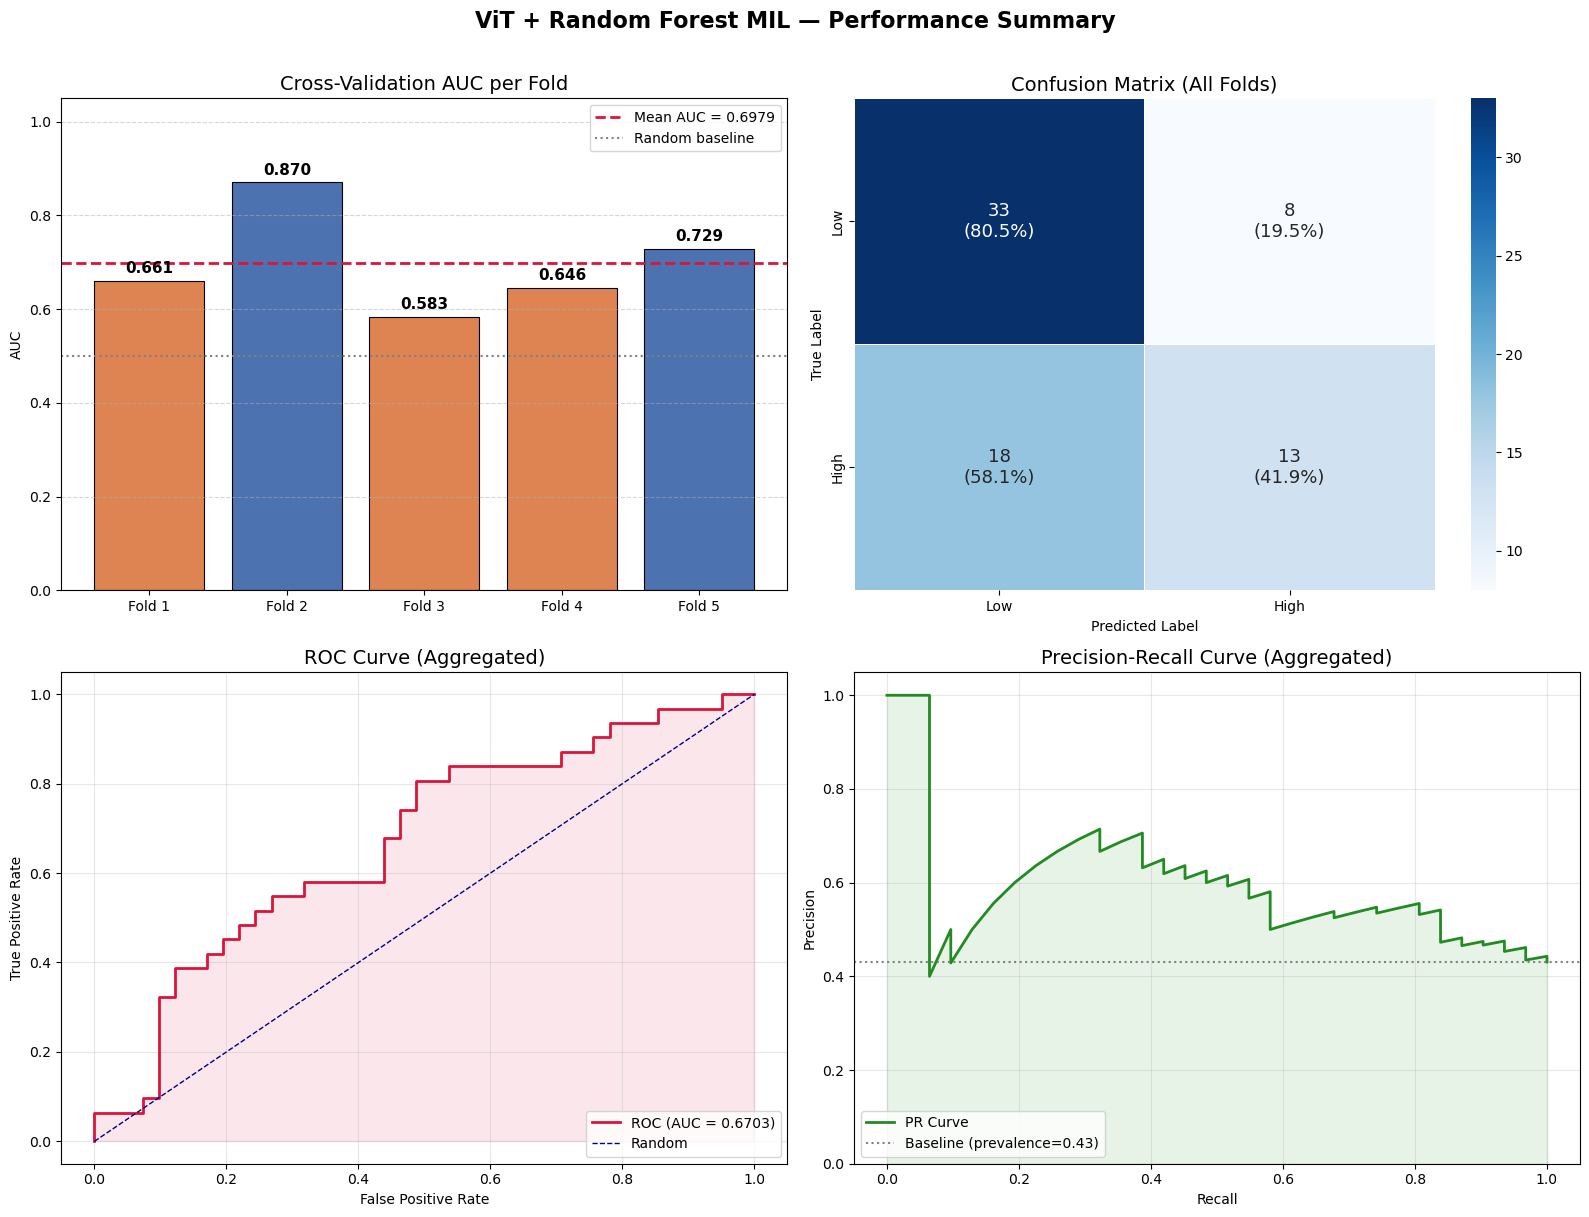

In [83]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, roc_curve, precision_recall_curve,
                             roc_auc_score, classification_report)

def plot_rf_performance(X_all, y_all, k_folds=5):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)

    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

    fold_aucs = []
    all_y_true, all_y_prob, all_y_pred = [], [], []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all)):
        clf = RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=4,
            class_weight='balanced',
            random_state=42
        )
        clf.fit(X_scaled[tr_idx], y_all[tr_idx])
        prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
        pred = clf.predict(X_scaled[val_idx])

        auc = roc_auc_score(y_all[val_idx], prob)
        fold_aucs.append(auc)

        all_y_true.extend(y_all[val_idx])
        all_y_prob.extend(prob)
        all_y_pred.extend(pred)

    all_y_true = np.array(all_y_true)
    all_y_prob = np.array(all_y_prob)
    all_y_pred = np.array(all_y_pred)

    # ---- 开始绘图 ----
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    plt.subplots_adjust(hspace=0.35, wspace=0.3)

    # --- A. 各折 AUC（替代训练曲线）---
    colors = ['#4C72B0' if auc >= np.mean(fold_aucs) else '#DD8452' for auc in fold_aucs]
    bars = axes[0, 0].bar([f'Fold {i+1}' for i in range(k_folds)], fold_aucs,
                           color=colors, edgecolor='black', linewidth=0.8)
    axes[0, 0].axhline(np.mean(fold_aucs), color='crimson', linestyle='--', lw=2,
                        label=f'Mean AUC = {np.mean(fold_aucs):.4f}')
    axes[0, 0].axhline(0.5, color='gray', linestyle=':', lw=1.5, label='Random baseline')
    for bar, auc in zip(bars, fold_aucs):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                         f'{auc:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylim(0, 1.05)
    axes[0, 0].set_title('Cross-Validation AUC per Fold', fontsize=14)
    axes[0, 0].set_ylabel('AUC')
    axes[0, 0].legend(fontsize=10)
    axes[0, 0].grid(True, linestyle='--', alpha=0.5, axis='y')

    # --- B. 混淆矩阵（汇总所有折）---
    cm = confusion_matrix(all_y_true, all_y_pred)
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i,j]}\n({cm_percent[i,j]:.1f}%)'
                        for j in range(cm.shape[1])] for i in range(cm.shape[0])])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[0, 1],
                xticklabels=['Low', 'High'], yticklabels=['Low', 'High'],
                annot_kws={"size": 13}, linewidths=0.5)
    axes[0, 1].set_title('Confusion Matrix (All Folds)', fontsize=14)
    axes[0, 1].set_xlabel('Predicted Label')
    axes[0, 1].set_ylabel('True Label')

    # --- C. ROC 曲线（汇总所有折的预测）---
    overall_auc = roc_auc_score(all_y_true, all_y_prob)
    fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
    axes[1, 0].plot(fpr, tpr, color='crimson', lw=2,
                     label=f'ROC (AUC = {overall_auc:.4f})')
    axes[1, 0].fill_between(fpr, tpr, alpha=0.1, color='crimson')
    axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random')
    axes[1, 0].set_title('ROC Curve (Aggregated)', fontsize=14)
    axes[1, 0].set_xlabel('False Positive Rate')
    axes[1, 0].set_ylabel('True Positive Rate')
    axes[1, 0].legend(loc='lower right', fontsize=10)
    axes[1, 0].grid(True, alpha=0.3)

    # --- D. PR 曲线 ---
    precision, recall, _ = precision_recall_curve(all_y_true, all_y_prob)
    baseline = all_y_true.sum() / len(all_y_true)
    axes[1, 1].plot(recall, precision, color='forestgreen', lw=2, label='PR Curve')
    axes[1, 1].axhline(baseline, color='gray', linestyle=':', lw=1.5,
                        label=f'Baseline (prevalence={baseline:.2f})')
    axes[1, 1].fill_between(recall, precision, alpha=0.1, color='forestgreen')
    axes[1, 1].set_title('Precision-Recall Curve (Aggregated)', fontsize=14)
    axes[1, 1].set_xlabel('Recall')
    axes[1, 1].set_ylabel('Precision')
    axes[1, 1].set_ylim(0, 1.05)
    axes[1, 1].legend(loc='lower left', fontsize=10)
    axes[1, 1].grid(True, alpha=0.3)

    # ---- 打印汇总报告 ----
    print(f"\n{'='*45}")
    print(f"  5-Fold CV Summary")
    print(f"{'='*45}")
    print(f"  Mean AUC : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"  Best AUC : {max(fold_aucs):.4f} (Fold {np.argmax(fold_aucs)+1})")
    print(f"  Aggregated AUC: {overall_auc:.4f}")
    print(f"\n{classification_report(all_y_true, all_y_pred, target_names=['Low', 'High'])}")

    plt.suptitle('ViT + Random Forest MIL — Performance Summary',
                 fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

# 执行绘图（复用之前的 X_all_best 和 y_all_best）
plot_rf_performance(X_all_best, y_all_best)


In [73]:
# 第一步：统计你的训练集
high_count = len(list(Path(FEATURE_PATH).glob("train/High/*.pt")))
low_count = len(list(Path(FEATURE_PATH).glob("train/Low/*.pt")))
print(f"训练集 High: {high_count}, Low: {low_count}")
print(f"验证集 High: {len(list(Path(FEATURE_PATH).glob('val/High/*.pt')))}, Low: {len(list(Path(FEATURE_PATH).glob('val/Low/*.pt')))}")


训练集 High: 22, Low: 30
验证集 High: 9, Low: 11


In [92]:
import torch
import numpy as np
from pathlib import Path
import re

def fix_coords(feature_root, patch_root):
    for pt_file in Path(feature_root).rglob("*.pt"):
        data = torch.load(pt_file)
        
        if len(data.get('coords', [])) > 0:
            continue
        
        parts = pt_file.parts
        split   = parts[-3]
        label   = parts[-2]
        patient = pt_file.stem
        
        patch_dir = Path(patch_root) / split / label / patient
        if not patch_dir.exists():
            print(f"⚠️ 找不到: {patch_dir}")
            continue
        
        patch_files = list(patch_dir.glob("*.png")) + list(patch_dir.glob("*.jpg"))
        
        coords = []
        for p in patch_files:
            # 匹配 x71492_y3027 格式
            m = re.search(r'_x(\d+)_y(\d+)', p.stem)
            if m:
                coords.append([int(m.group(1)), int(m.group(2))])
            else:
                coords.append([0, 0])
        
        data['coords'] = np.array(coords)
        torch.save(data, pt_file)
        print(f"✅ {pt_file.name}: 补充了 {len(coords)} 个坐标")

fix_coords(
    feature_root=r"G:\WSLearning\Data\features.vit",
    patch_root=r"G:\WSLearning\Data"
)


✅ TCGA-A6-2678.pt: 补充了 995 个坐标
✅ TCGA-A6-2684.pt: 补充了 1679 个坐标
✅ TCGA-A6-5661.pt: 补充了 1012 个坐标
✅ TCGA-A6-6140.pt: 补充了 1490 个坐标
✅ TCGA-A6-6141.pt: 补充了 2542 个坐标
✅ TCGA-A6-6649.pt: 补充了 1486 个坐标
✅ TCGA-A6-6651.pt: 补充了 1026 个坐标
✅ TCGA-A6-A5ZU.pt: 补充了 1141 个坐标
✅ TCGA-AA-3520.pt: 补充了 2404 个坐标
✅ TCGA-AA-3527.pt: 补充了 2236 个坐标
✅ TCGA-AA-3819.pt: 补充了 2312 个坐标
✅ TCGA-AA-3850.pt: 补充了 1738 个坐标
✅ TCGA-AA-3856.pt: 补充了 3943 个坐标
✅ TCGA-AA-A00D.pt: 补充了 2088 个坐标
✅ TCGA-AA-A00O.pt: 补充了 2072 个坐标
✅ TCGA-AA-A00U.pt: 补充了 1481 个坐标
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-D5-6929
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-D5-6930
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-D5-6931
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-F4-6703
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-F4-6854
⚠️ 找不到: G:\WSLearning\Data\train\High\TCGA-G4-6306
✅ TCGA-A6-2683.pt: 补充了 1354 个坐标
✅ TCGA-A6-5664.pt: 补充了 1439 个坐标
✅ TCGA-AA-3514.pt: 补充了 3287 个坐标
✅ TCGA-AA-3517.pt: 补充了 3770 个坐标
✅ TCGA-AA-3521.pt: 补充了 6185 个坐标
✅ TCGA-AA-3522.pt: 补充了 

使用设备: cuda
加载特征...
总样本: 72, High: 31, Low: 41, 特征维度: 2304
正在计算 t-SNE（约需30秒）...


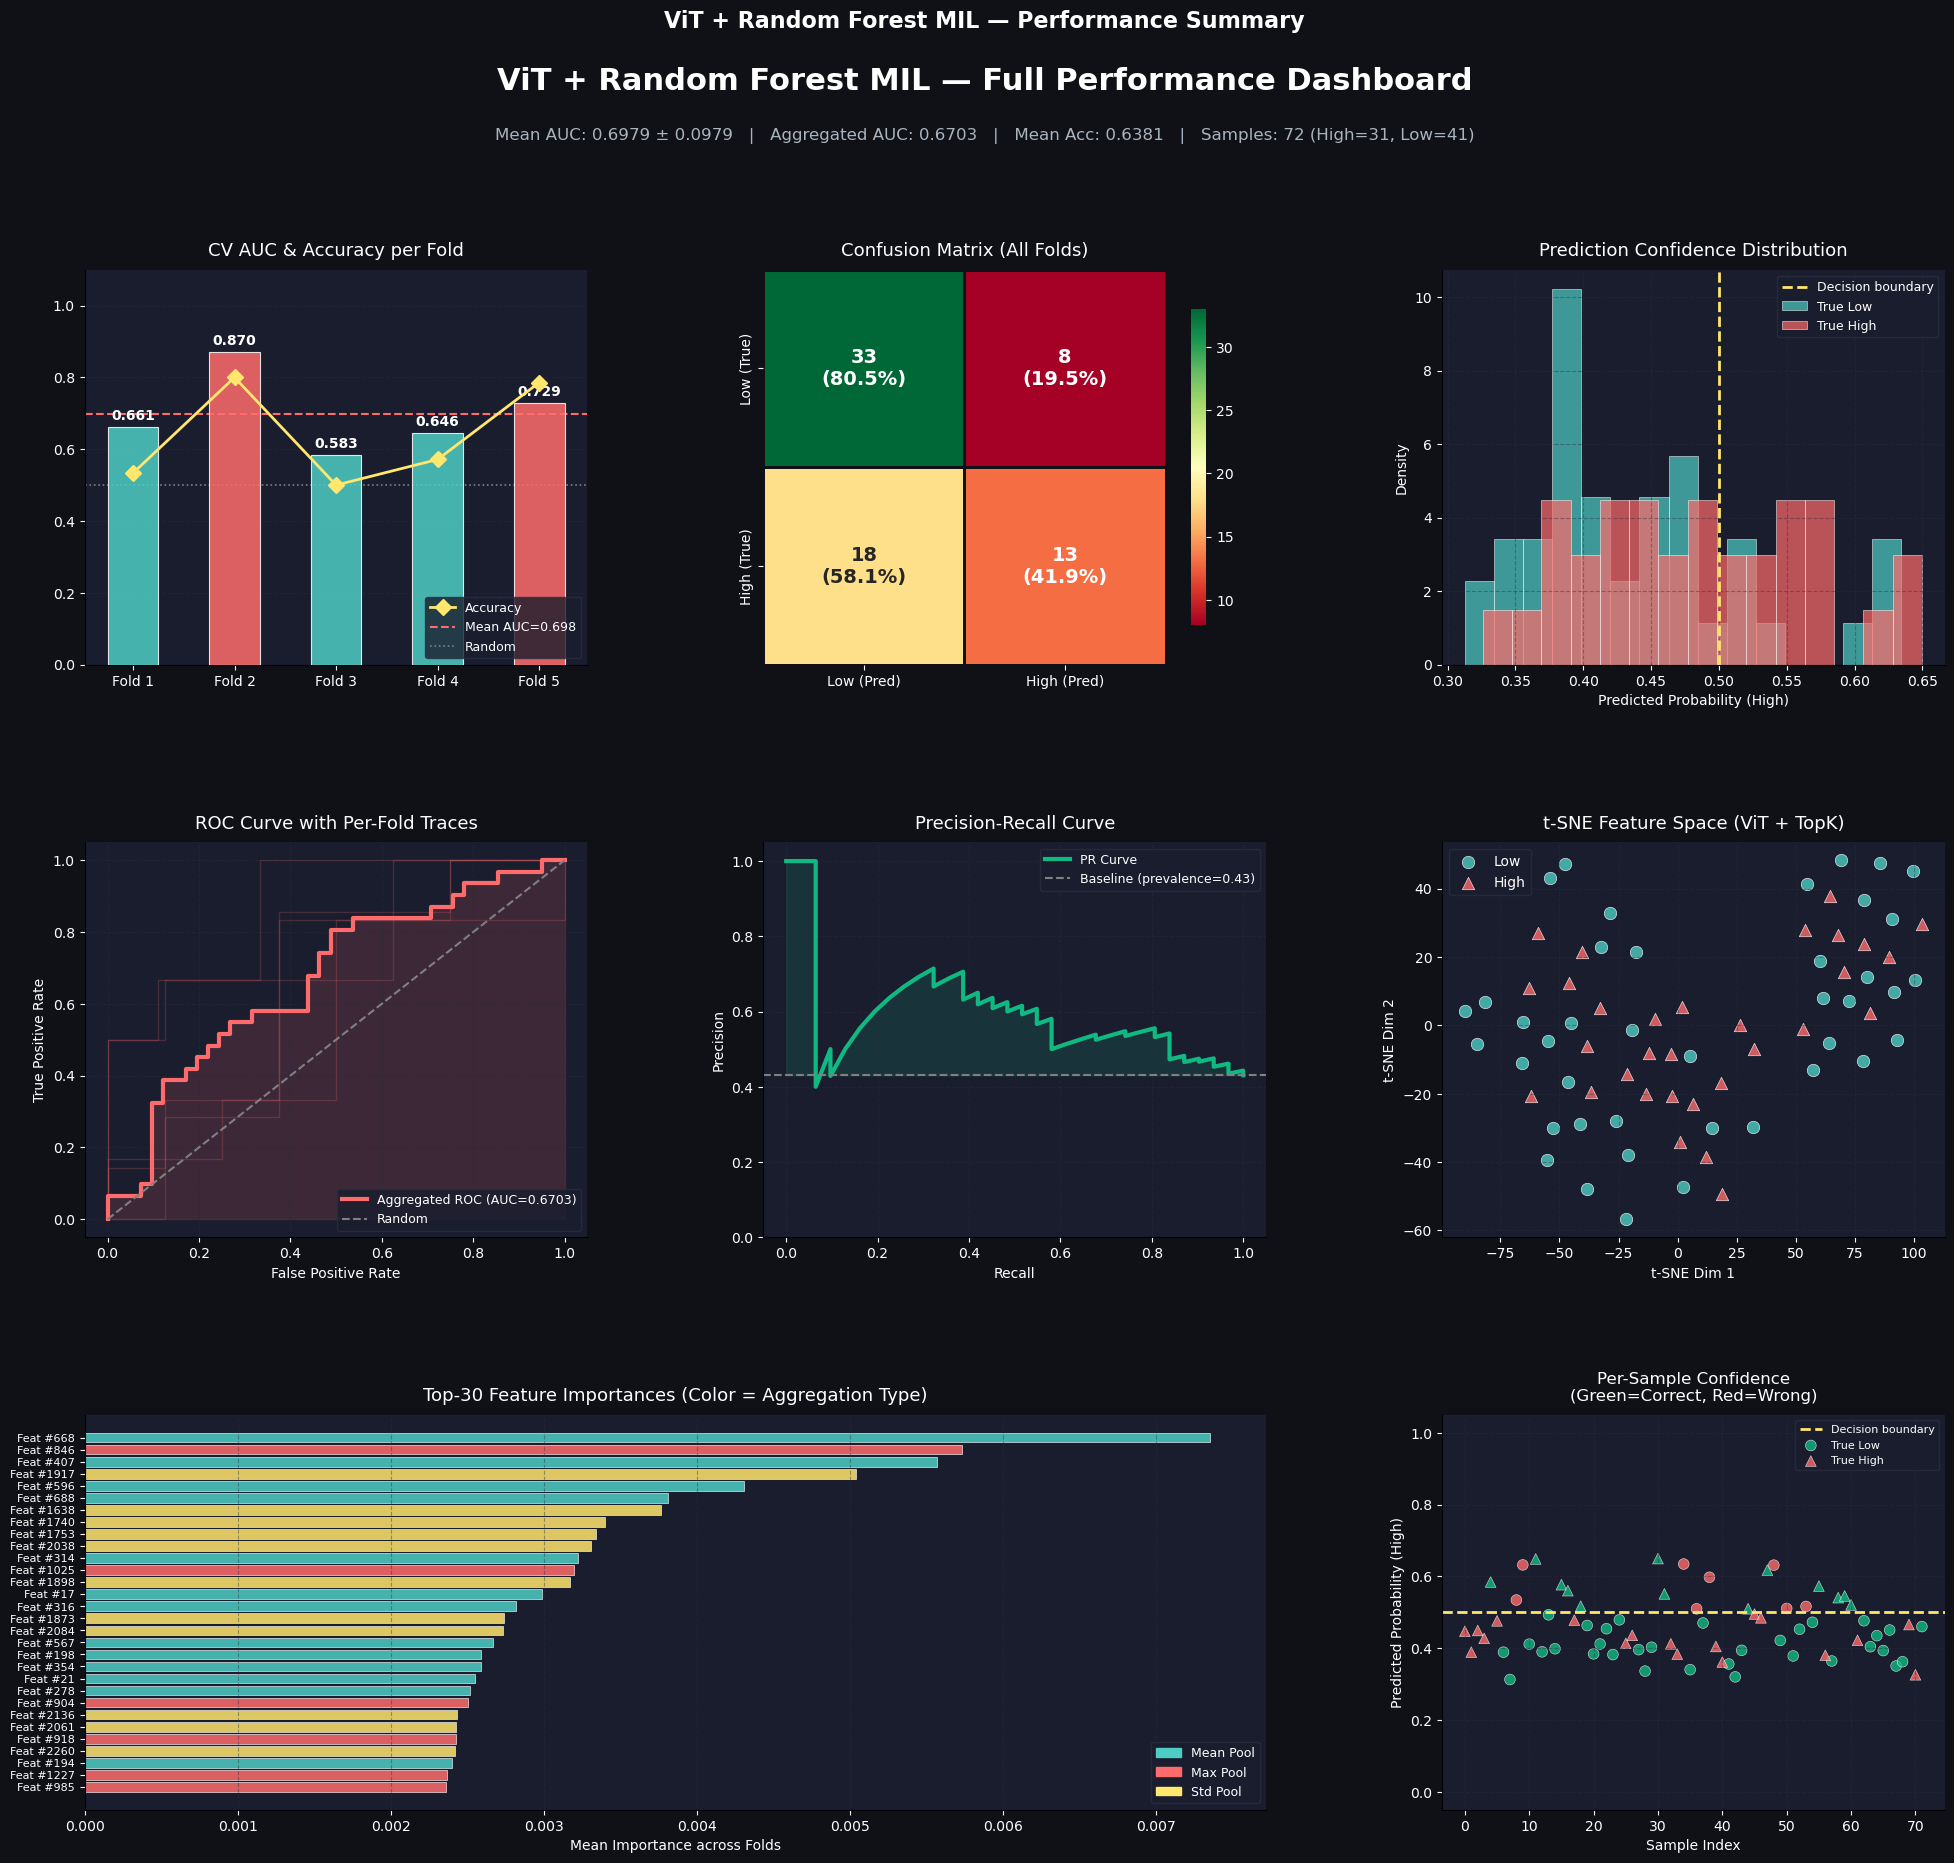


  Performance Summary
  Mean AUC  : 0.6979 ± 0.0979
  Best Fold : Fold 2 (AUC=0.8704)
  Aggregated AUC : 0.6703

              precision    recall  f1-score   support

         Low       0.65      0.80      0.72        41
        High       0.62      0.42      0.50        31

    accuracy                           0.64        72
   macro avg       0.63      0.61      0.61        72
weighted avg       0.63      0.64      0.62        72



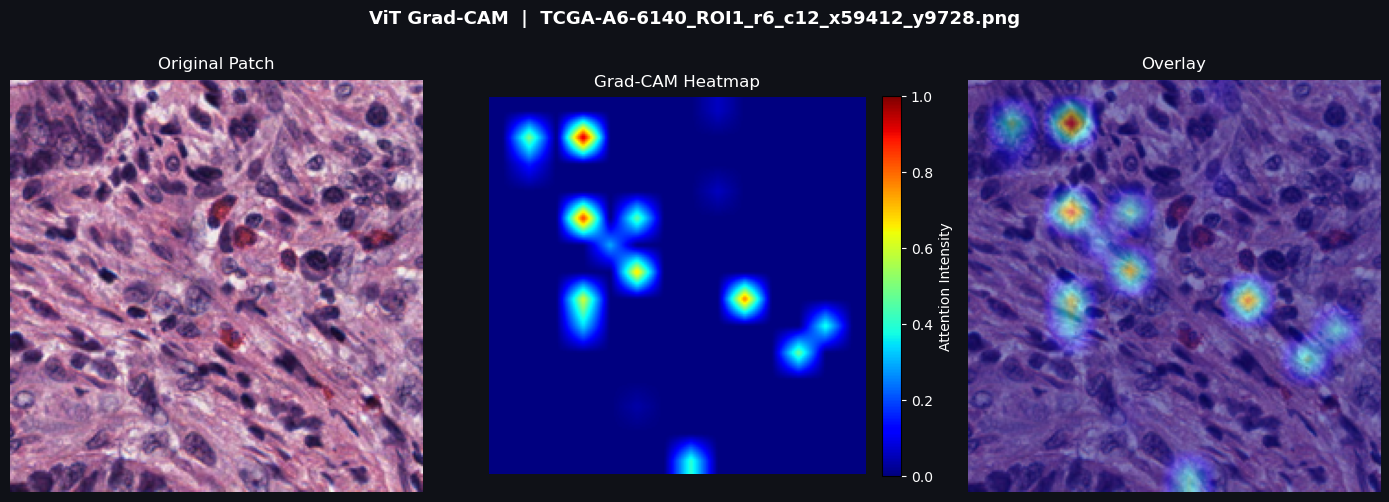

重建 TCGA-AA-A01V (6112×8851)，共 6939 个 Patch...


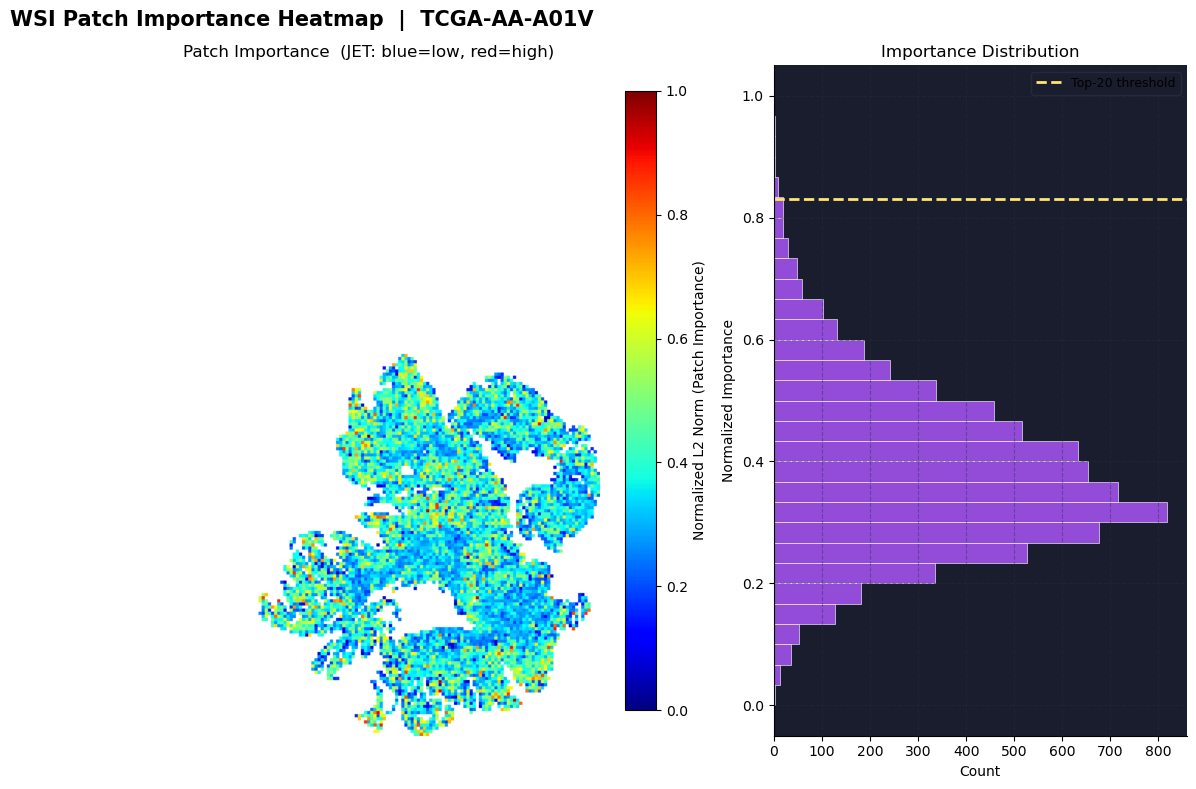

✅ 已保存: wsi_heatmap_rf.png
   Top-5 坐标: [[ 37981  60955]
 [ 47709  73243]
 [ 55901  87579]
 [ 49757 101403]
 [ 62045 104475]]


In [46]:
# ============================================================
# 完整代码：ViT + RandomForest MIL 病理分级系统
# ============================================================

# %% [1] 导入依赖
%matplotlib inline
import os, re, cv2, torch, timm, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from torchvision import transforms
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, roc_curve, precision_recall_curve,
                             roc_auc_score, classification_report)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from matplotlib.colors import Normalize

warnings.filterwarnings('ignore')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

# ============================================================
# %% [2] 路径配置
# ============================================================
FEATURE_ROOT = r"G:\WSLearning\Data\features.vit"   # ViT 特征存放路径
PATCH_ROOT   = r"G:\WSLearning\Data"                # 原始 patch 存放路径

# ============================================================
# %% [3] 修复坐标（features.vit 提取时坐标为空时运行）
# ============================================================
def fix_coords(feature_root, patch_root):
    """
    根据原始 patch 文件名（格式：TCGA-XX_ROI1_r4_c21_x71492_y3027.png）
    补充 .pt 文件里为空的 coords 字段
    """
    fixed = 0
    for pt_file in Path(feature_root).rglob("*.pt"):
        data = torch.load(pt_file)
        if len(data.get('coords', [])) > 0:
            continue

        parts   = pt_file.parts
        split   = parts[-3]
        label   = parts[-2]
        patient = pt_file.stem

        patch_dir = Path(patch_root) / split / label / patient
        if not patch_dir.exists():
            print(f"⚠️ 找不到: {patch_dir}")
            continue

        patch_files = list(patch_dir.glob("*.png")) + list(patch_dir.glob("*.jpg"))
        coords = []
        for p in patch_files:
            m = re.search(r'_x(\d+)_y(\d+)', p.stem)
            coords.append([int(m.group(1)), int(m.group(2))] if m else [0, 0])

        data['coords'] = np.array(coords)
        torch.save(data, pt_file)
        fixed += 1
        print(f"✅ {pt_file.name}: 补充了 {len(coords)} 个坐标")

    print(f"\n共修复 {fixed} 个文件")

# fix_coords(FEATURE_ROOT, PATCH_ROOT)  # 首次运行时取消注释

# ============================================================
# %% [4] 特征加载（Top-K 聚合）
# ============================================================
def load_topk_features(feature_root, k=20):
    """
    加载所有 .pt 文件，用 L2 范数选 Top-K patch，
    做 Mean + Max + Std 三种聚合，拼接成 2304 维病人级特征
    """
    X, y = [], []
    for pt_file in Path(feature_root).rglob("*.pt"):
        data  = torch.load(pt_file)
        feats = data['feats']                         # [N, 768]
        norms = np.linalg.norm(feats, axis=1)
        topk_idx = np.argsort(norms)[-k:]
        topk_feats = feats[topk_idx]
        combined = np.concatenate([
            topk_feats.mean(axis=0),
            topk_feats.max(axis=0),
            topk_feats.std(axis=0)
        ])
        label = 1 if 'HIGH' in str(pt_file).upper() else 0
        X.append(combined)
        y.append(label)
    return np.array(X), np.array(y)

print("加载特征...")
X_train, y_train = load_topk_features(Path(FEATURE_ROOT) / "train", k=20)
X_val,   y_val   = load_topk_features(Path(FEATURE_ROOT) / "val",   k=20)
X_all = np.vstack([X_train, X_val])
y_all = np.concatenate([y_train, y_val])
print(f"总样本: {len(X_all)}, High: {y_all.sum()}, Low: {(y_all==0).sum()}, 特征维度: {X_all.shape[1]}")

# 保存供后续直接使用
X_all_best = X_all
y_all_best = y_all

# ============================================================
# %% [5] 全局绘图风格
# ============================================================
plt.rcParams.update({
    'font.family'       : 'DejaVu Sans',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'figure.facecolor'  : '#0F1117',
    'axes.facecolor'    : '#1A1D2E',
    'axes.labelcolor'   : 'white',
    'xtick.color'       : 'white',
    'ytick.color'       : 'white',
    'text.color'        : 'white',
    'grid.color'        : '#2A2D3E',
    'grid.alpha'        : 0.5,
})

COLORS = {
    'high'  : '#FF6B6B',
    'low'   : '#4ECDC4',
    'accent': '#FFE66D',
    'purple': '#A855F7',
    'blue'  : '#3B82F6',
    'green' : '#10B981',
    'bg'    : '#0F1117',
    'card'  : '#1A1D2E',
    'border': '#2A2D3E',
}

# ============================================================
# %% [6] 性能可视化 Dashboard
# ============================================================
def plot_fancy_rf_performance(X_all, y_all, k_folds=5):
    scaler   = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)
    skf      = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

    fold_aucs, fold_accs      = [], []
    all_y_true, all_y_prob, all_y_pred = [], [], []
    feature_importances       = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all)):
        clf = RandomForestClassifier(
            n_estimators=500, max_depth=None,
            min_samples_leaf=4, class_weight='balanced', random_state=42
        )
        clf.fit(X_scaled[tr_idx], y_all[tr_idx])
        prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
        pred = clf.predict(X_scaled[val_idx])

        fold_aucs.append(roc_auc_score(y_all[val_idx], prob))
        fold_accs.append((pred == y_all[val_idx]).mean())
        all_y_true.extend(y_all[val_idx])
        all_y_prob.extend(prob)
        all_y_pred.extend(pred)
        feature_importances.append(clf.feature_importances_)

    all_y_true      = np.array(all_y_true)
    all_y_prob      = np.array(all_y_prob)
    all_y_pred      = np.array(all_y_pred)
    mean_importance = np.mean(feature_importances, axis=0)
    overall_auc     = roc_auc_score(all_y_true, all_y_prob)

    fig = plt.figure(figsize=(24, 20), facecolor=COLORS['bg'])
    gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

    fig.text(0.5, 0.97,
             'ViT + Random Forest MIL — Full Performance Dashboard',
             ha='center', fontsize=22, fontweight='bold', color='white')
    fig.text(0.5, 0.945,
             f"Mean AUC: {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}   |   "
             f"Aggregated AUC: {overall_auc:.4f}   |   "
             f"Mean Acc: {np.mean(fold_accs):.4f}   |   "
             f"Samples: {len(y_all)} (High={y_all.sum()}, Low={(y_all==0).sum()})",
             ha='center', fontsize=12, color='#AAB4BE')

    # --- A. 各折 AUC + Accuracy ---
    ax1 = fig.add_subplot(gs[0, 0])
    x   = np.arange(k_folds)
    bar_colors = [COLORS['high'] if a >= np.mean(fold_aucs) else COLORS['low'] for a in fold_aucs]
    bars = ax1.bar(x, fold_aucs, color=bar_colors, edgecolor='white',
                   linewidth=0.8, width=0.5, zorder=3, alpha=0.85)
    ax1.plot(x, fold_accs, color=COLORS['accent'], marker='D',
             linewidth=2, markersize=8, label='Accuracy', zorder=4)
    ax1.axhline(np.mean(fold_aucs), color=COLORS['high'], linestyle='--',
                lw=1.5, label=f"Mean AUC={np.mean(fold_aucs):.3f}", zorder=2)
    ax1.axhline(0.5, color='gray', linestyle=':', lw=1.2, label='Random', zorder=2)
    for bar, auc in zip(bars, fold_aucs):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012,
                 f'{auc:.3f}', ha='center', va='bottom', fontsize=10,
                 fontweight='bold', color='white')
    ax1.set_ylim(0, 1.1)
    ax1.set_xticks(x)
    ax1.set_xticklabels([f'Fold {i+1}' for i in range(k_folds)])
    ax1.set_title('CV AUC & Accuracy per Fold', fontsize=13, pad=10, color='white')
    ax1.legend(fontsize=9, loc='lower right',
               facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax1.grid(True, axis='y', linestyle='--', alpha=0.4)

    # --- B. 混淆矩阵 ---
    ax2  = fig.add_subplot(gs[0, 1])
    cm   = confusion_matrix(all_y_true, all_y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot  = np.array([[f'{cm[i,j]}\n({cm_pct[i,j]:.1f}%)'
                        for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt='', cmap='RdYlGn', ax=ax2,
                xticklabels=['Low (Pred)', 'High (Pred)'],
                yticklabels=['Low (True)', 'High (True)'],
                annot_kws={"size": 14, "weight": "bold"},
                linewidths=2, linecolor=COLORS['bg'],
                cbar_kws={'shrink': 0.8})
    ax2.set_title('Confusion Matrix (All Folds)', fontsize=13, pad=10, color='white')
    ax2.tick_params(colors='white')

    # --- C. 置信度分布 ---
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.hist(all_y_prob[all_y_true==0], bins=15, alpha=0.7, color=COLORS['low'],
             label='True Low', density=True, edgecolor='white', linewidth=0.5)
    ax3.hist(all_y_prob[all_y_true==1], bins=15, alpha=0.7, color=COLORS['high'],
             label='True High', density=True, edgecolor='white', linewidth=0.5)
    ax3.axvline(0.5, color=COLORS['accent'], linestyle='--', lw=2, label='Decision boundary')
    ax3.set_title('Prediction Confidence Distribution', fontsize=13, pad=10, color='white')
    ax3.set_xlabel('Predicted Probability (High)')
    ax3.set_ylabel('Density')
    ax3.legend(fontsize=9, facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax3.grid(True, linestyle='--', alpha=0.4)

    # --- D. ROC 曲线（带每折轨迹）---
    ax4 = fig.add_subplot(gs[1, 0])
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all)):
        clf = RandomForestClassifier(n_estimators=500, max_depth=None,
                                     min_samples_leaf=4, class_weight='balanced',
                                     random_state=42)
        clf.fit(X_scaled[tr_idx], y_all[tr_idx])
        prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
        fpr_f, tpr_f, _ = roc_curve(y_all[val_idx], prob)
        ax4.plot(fpr_f, tpr_f, color=COLORS['high'], alpha=0.2, lw=1)

    fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
    ax4.plot(fpr, tpr, color=COLORS['high'], lw=3,
             label=f'Aggregated ROC (AUC={overall_auc:.4f})')
    ax4.fill_between(fpr, tpr, alpha=0.15, color=COLORS['high'])
    ax4.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random')
    ax4.set_title('ROC Curve with Per-Fold Traces', fontsize=13, pad=10, color='white')
    ax4.set_xlabel('False Positive Rate')
    ax4.set_ylabel('True Positive Rate')
    ax4.legend(fontsize=9, loc='lower right',
               facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax4.grid(True, linestyle='--', alpha=0.4)

    # --- E. PR 曲线 ---
    ax5 = fig.add_subplot(gs[1, 1])
    precision, recall, _ = precision_recall_curve(all_y_true, all_y_prob)
    baseline = all_y_true.sum() / len(all_y_true)
    ax5.plot(recall, precision, color=COLORS['green'], lw=3, label='PR Curve')
    ax5.fill_between(recall, precision, baseline, alpha=0.15, color=COLORS['green'])
    ax5.axhline(baseline, color='gray', linestyle='--', lw=1.5,
                label=f'Baseline (prevalence={baseline:.2f})')
    ax5.set_title('Precision-Recall Curve', fontsize=13, pad=10, color='white')
    ax5.set_xlabel('Recall')
    ax5.set_ylabel('Precision')
    ax5.set_ylim(0, 1.05)
    ax5.legend(fontsize=9, facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax5.grid(True, linestyle='--', alpha=0.4)

    # --- F. t-SNE ---
    ax6 = fig.add_subplot(gs[1, 2])
    print("正在计算 t-SNE（约需30秒）...")
    tsne   = TSNE(n_components=2, random_state=42, perplexity=min(20, len(y_all)//3))
    X_tsne = tsne.fit_transform(X_scaled)
    ax6.scatter(X_tsne[y_all==0, 0], X_tsne[y_all==0, 1],
                c=COLORS['low'],  label='Low',  alpha=0.8, s=80,
                edgecolors='white', linewidth=0.5)
    ax6.scatter(X_tsne[y_all==1, 0], X_tsne[y_all==1, 1],
                c=COLORS['high'], label='High', alpha=0.8, s=80,
                edgecolors='white', linewidth=0.5, marker='^')
    ax6.set_title('t-SNE Feature Space (ViT + TopK)', fontsize=13, pad=10, color='white')
    ax6.set_xlabel('t-SNE Dim 1')
    ax6.set_ylabel('t-SNE Dim 2')
    ax6.legend(fontsize=10, facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax6.grid(True, linestyle='--', alpha=0.4)

    # --- G. 特征重要性 ---
    ax7    = fig.add_subplot(gs[2, :2])
    top_n  = 30
    top_idx = np.argsort(mean_importance)[-top_n:][::-1]
    top_vals = mean_importance[top_idx]
    dim    = X_all.shape[1] // 3
    seg_colors = [COLORS['low'] if i < dim else COLORS['high'] if i < 2*dim
                  else COLORS['accent'] for i in top_idx]
    ax7.barh(range(top_n), top_vals[::-1],
             color=seg_colors[::-1], edgecolor='white', linewidth=0.5, alpha=0.85)
    ax7.set_yticks(range(top_n))
    ax7.set_yticklabels([f'Feat #{top_idx[::-1][i]}' for i in range(top_n)], fontsize=8)
    ax7.set_title(f'Top-{top_n} Feature Importances (Color = Aggregation Type)',
                  fontsize=13, pad=10, color='white')
    ax7.set_xlabel('Mean Importance across Folds')
    ax7.legend(handles=[
        mpatches.Patch(color=COLORS['low'],    label='Mean Pool'),
        mpatches.Patch(color=COLORS['high'],   label='Max Pool'),
        mpatches.Patch(color=COLORS['accent'], label='Std Pool'),
    ], fontsize=9, facecolor=COLORS['card'], edgecolor=COLORS['border'], loc='lower right')
    ax7.grid(True, axis='x', linestyle='--', alpha=0.4)

    # --- H. 逐样本置信度 ---
    ax8 = fig.add_subplot(gs[2, 2])
    correct_mask = all_y_true == all_y_pred
    for mask, marker, label_str in [(all_y_true==0, 'o', 'True Low'),
                                     (all_y_true==1, '^', 'True High')]:
        colors_s = [COLORS['green'] if c else COLORS['high'] for c in correct_mask[mask]]
        ax8.scatter(np.where(mask)[0], all_y_prob[mask],
                    c=colors_s, marker=marker, s=60, alpha=0.8,
                    edgecolors='white', linewidth=0.4, label=label_str)
    ax8.axhline(0.5, color=COLORS['accent'], linestyle='--', lw=2, label='Decision boundary')
    ax8.set_title('Per-Sample Confidence\n(Green=Correct, Red=Wrong)',
                  fontsize=12, pad=10, color='white')
    ax8.set_xlabel('Sample Index')
    ax8.set_ylabel('Predicted Probability (High)')
    ax8.set_ylim(-0.05, 1.05)
    ax8.legend(fontsize=8, facecolor=COLORS['card'], edgecolor=COLORS['border'])
    ax8.grid(True, linestyle='--', alpha=0.4)

    plt.suptitle('ViT + Random Forest MIL — Performance Summary',
                 fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('mil_performance_dashboard.png', dpi=150,
                bbox_inches='tight', facecolor=COLORS['bg'])
    plt.show()

    print(f"\n{'='*50}")
    print(f"  Performance Summary")
    print(f"{'='*50}")
    print(f"  Mean AUC  : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"  Best Fold : Fold {np.argmax(fold_aucs)+1} (AUC={max(fold_aucs):.4f})")
    print(f"  Aggregated AUC : {overall_auc:.4f}")
    print(f"\n{classification_report(all_y_true, all_y_pred, target_names=['Low','High'])}")

plot_fancy_rf_performance(X_all_best, y_all_best)

# ============================================================
# %% [7] ViT Grad-CAM（单张 Patch）
# ============================================================
class ViTGradCAM:
    def __init__(self, model):
        self.model      = model
        self.gradients  = None
        self.activations = None
        target_layer = model.blocks[-1].norm1
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.mean().backward()

        grads   = self.gradients[0, 1:, :]    # [196, 768]
        acts    = self.activations[0, 1:, :]  # [196, 768]
        weights = grads.mean(dim=-1)           # [196]
        cam     = (weights * acts.mean(dim=-1)).detach().cpu().numpy()
        cam     = cam.reshape(14, 14)
        cam     = np.maximum(cam, 0)
        cam     = cv2.resize(cam, (224, 224))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


VIT_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])


def show_vit_gradcam(patch_path, dark_theme=True):
    vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
    vit_model.to(device).eval()
    cam_gen = ViTGradCAM(vit_model)

    img_pil      = Image.open(patch_path).convert('RGB')
    input_tensor = VIT_TRANSFORM(img_pil).unsqueeze(0).to(device)

    mask      = cam_gen.generate(input_tensor)
    heatmap   = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)  # 经典 JET 配色
    raw_img   = np.array(img_pil.resize((224, 224)))
    overlayed = cv2.addWeighted(raw_img, 0.55,
                                cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), 0.45, 0)

    bg, tc = ('#0F1117', 'white') if dark_theme else ('white', 'black')
    fig, axes = plt.subplots(1, 3, figsize=(14, 5), facecolor=bg)
    fig.suptitle(f'ViT Grad-CAM  |  {Path(patch_path).name}',
                 fontsize=13, color=tc, fontweight='bold', y=1.02)

    for ax, title, img in zip(
        axes,
        ['Original Patch', 'Grad-CAM Heatmap', 'Overlay'],
        [raw_img, cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), overlayed]
    ):
        ax.imshow(img)
        ax.set_title(title, color=tc, fontsize=12, pad=8)
        ax.axis('off')
        ax.set_facecolor(bg)

    sm   = plt.cm.ScalarMappable(cmap='jet', norm=Normalize(vmin=0, vmax=1))
    cbar = fig.colorbar(sm, ax=axes[1], fraction=0.046, pad=0.04)
    cbar.set_label('Attention Intensity', color=tc, fontsize=10)
    cbar.ax.yaxis.set_tick_params(color=tc)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color=tc)

    plt.tight_layout()
    plt.savefig('gradcam_output.png', dpi=150, bbox_inches='tight', facecolor=bg)
    plt.show()


def show_patient_topk_gradcam(patient_pt_path, patch_folder, top_k=6):
    """展示某个病人 Top-K 最重要 patch 的 Grad-CAM"""
    data        = torch.load(patient_pt_path)
    feats       = data['feats']
    coords      = data['coords']
    norms       = np.linalg.norm(feats, axis=1)
    topk_idx    = np.argsort(norms)[-top_k:][::-1]
    topk_coords = coords[topk_idx]

    vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
    vit_model.to(device).eval()
    cam_gen = ViTGradCAM(vit_model)

    bg  = '#0F1117'
    fig, axes = plt.subplots(top_k, 3, figsize=(14, top_k * 4), facecolor=bg)
    patient_name = Path(patient_pt_path).stem
    fig.suptitle(f'Top-{top_k} Patches Grad-CAM  |  {patient_name}',
                 fontsize=15, color='white', fontweight='bold', y=1.01)

    for row, (idx, coord) in enumerate(zip(topk_idx, topk_coords)):
        x, y = coord
        patch_files = (list(Path(patch_folder).glob(f'*_x{x}_y{y}.png')) +
                       list(Path(patch_folder).glob(f'*_x{x}_y{y}.jpg')))

        if not patch_files:
            for ax in axes[row]: ax.axis('off')
            continue

        img_pil      = Image.open(str(patch_files[0])).convert('RGB')
        input_tensor = VIT_TRANSFORM(img_pil).unsqueeze(0).to(device)
        mask         = cam_gen.generate(input_tensor)
        heatmap      = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        raw_img      = np.array(img_pil.resize((224, 224)))
        overlayed    = cv2.addWeighted(raw_img, 0.55,
                                       cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), 0.45, 0)

        for ax, img, title in zip(
            axes[row],
            [raw_img, cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), overlayed],
            [f'Patch #{idx} (norm={norms[idx]:.2f})', 'Heatmap', 'Overlay']
        ):
            ax.imshow(img)
            ax.set_title(title, color='white', fontsize=10)
            ax.axis('off')
            ax.set_facecolor(bg)

    plt.tight_layout()
    plt.savefig('patient_gradcam.png', dpi=120, bbox_inches='tight', facecolor=bg)
    plt.show()


# 调用示例
show_vit_gradcam(
    r"G:\WSLearning\Data\train\High\TCGA-A6-6140\TCGA-A6-6140_ROI1_r6_c12_x59412_y9728.png"
)

# show_patient_topk_gradcam(
#     patient_pt_path=r"G:\WSLearning\Data\features.vit\train\High\TCGA-A6-6140.pt",
#     patch_folder=r"G:\WSLearning\Data\train\High\TCGA-A6-6140",
#     top_k=6
# )

# ============================================================
# %% [8] WSI 热图重建（JET 配色 + 无缝拼接）
# ============================================================
def rebuild_wsi_heatmap_rf(patient_id, pt_file_path, save_path, dark_theme=True):
    data   = torch.load(pt_file_path)
    feats  = data['feats']
    coords = data['coords']

    if len(coords) == 0 or coords.shape[0] == 0:
        print(f"⚠️ {patient_id} 的 coords 为空，请先运行 fix_coords()，跳过。")
        return

    norms      = np.linalg.norm(feats, axis=1)
    A_norm     = (norms - norms.min()) / (norms.max() - norms.min() + 1e-8)

    scale      = 0.08
    patch_size = 512
    max_x, max_y = np.max(coords, axis=0)
    canvas_h   = int((max_y + patch_size) * scale) + 2
    canvas_w   = int((max_x + patch_size) * scale) + 2

    bg_color = (15, 17, 23) if dark_theme else (255, 255, 255)
    canvas   = np.full((canvas_h, canvas_w, 3), bg_color, dtype=np.uint8)

    print(f"重建 {patient_id} ({canvas_w}×{canvas_h})，共 {len(coords)} 个 Patch...")

    # 按重要性从低到高绘制，高重要性压在最上层
    for i in np.argsort(A_norm):
        x, y      = coords[i]
        color_val = int(A_norm[i] * 255)
        color     = cv2.applyColorMap(
            np.array([[color_val]], dtype=np.uint8), cv2.COLORMAP_JET   # 经典 JET 配色
        )[0][0].tolist()

        x0 = int(x * scale)
        y0 = int(y * scale)
        x1 = int((x + patch_size) * scale) + 1   # +1 消除缝隙
        y1 = int((y + patch_size) * scale) + 1
        cv2.rectangle(canvas, (x0, y0), (x1, y1), color, -1)

    # Top-20 加白色边框高亮
    for i in np.argsort(A_norm)[-20:]:
        x, y = coords[i]
        cv2.rectangle(canvas,
                      (int(x * scale), int(y * scale)),
                      (int((x + patch_size) * scale) + 1, int((y + patch_size) * scale) + 1),
                      (255, 255, 255), 1)

    cv2.imwrite(save_path, canvas)

    bg, tc = ('#0F1117', 'white') if dark_theme else ('white', 'black')
    fig, axes = plt.subplots(1, 2, figsize=(18, 8), facecolor=bg,
                              gridspec_kw={'width_ratios': [3, 1]})
    fig.suptitle(f'WSI Patch Importance Heatmap  |  {patient_id}',
                 fontsize=15, color=tc, fontweight='bold')

    axes[0].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Patch Importance  (JET: blue=low, red=high)',
                      color=tc, fontsize=12)
    axes[0].axis('off')
    axes[0].set_facecolor(bg)

    sm   = plt.cm.ScalarMappable(cmap='jet', norm=Normalize(vmin=0, vmax=1))  # JET 颜色条
    cbar = fig.colorbar(sm, ax=axes[0], fraction=0.025, pad=0.02)
    cbar.set_label('Normalized L2 Norm (Patch Importance)', color=tc, fontsize=10)
    cbar.ax.yaxis.set_tick_params(color=tc)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color=tc)

    axes[1].hist(A_norm, bins=30, color='#A855F7', edgecolor='white',
                 linewidth=0.5, orientation='horizontal', alpha=0.85)
    axes[1].axhline(A_norm[np.argsort(A_norm)[-20]], color='#FFE66D',
                    linestyle='--', lw=2, label='Top-20 threshold')
    axes[1].set_title('Importance Distribution', color=tc, fontsize=12)
    axes[1].set_xlabel('Count', color=tc)
    axes[1].set_ylabel('Normalized Importance', color=tc)
    axes[1].tick_params(colors=tc)
    axes[1].set_facecolor('#1A1D2E')
    axes[1].legend(fontsize=9, facecolor='#1A1D2E', edgecolor='#2A2D3E', labelcolor=tc)
    axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(save_path.replace('.png', '_display.png'),
                dpi=150, bbox_inches='tight', facecolor=bg)
    plt.show()
    print(f"✅ 已保存: {save_path}")
    print(f"   Top-5 坐标: {coords[np.argsort(A_norm)[-5:][::-1]]}")


# 单个病人调用示例
rebuild_wsi_heatmap_rf(
    patient_id   = "TCGA-AA-A01V",
    pt_file_path = r"G:\WSLearning\Data\features.vit\val\High\TCGA-AA-A01V.pt",
    save_path    = "wsi_heatmap_rf.png",
    dark_theme   = False
)

# 批量处理
# for pt_file in Path(FEATURE_ROOT + r"\val").rglob("*.pt"):
#     label = "High" if "High" in str(pt_file) else "Low"
#     rebuild_wsi_heatmap_rf(
#         patient_id   = f"[{label}] {pt_file.stem}",
#         pt_file_path = str(pt_file),
#         save_path    = f"wsi_{pt_file.stem}.png",
#         dark_theme   = True
#     )
#G:\WSLearning\Data\features.vit\val\High\TCGA-AA-A01V.pt

重建 TCGA-AA-A01V (6112×8851)，共 6939 个 Patch...


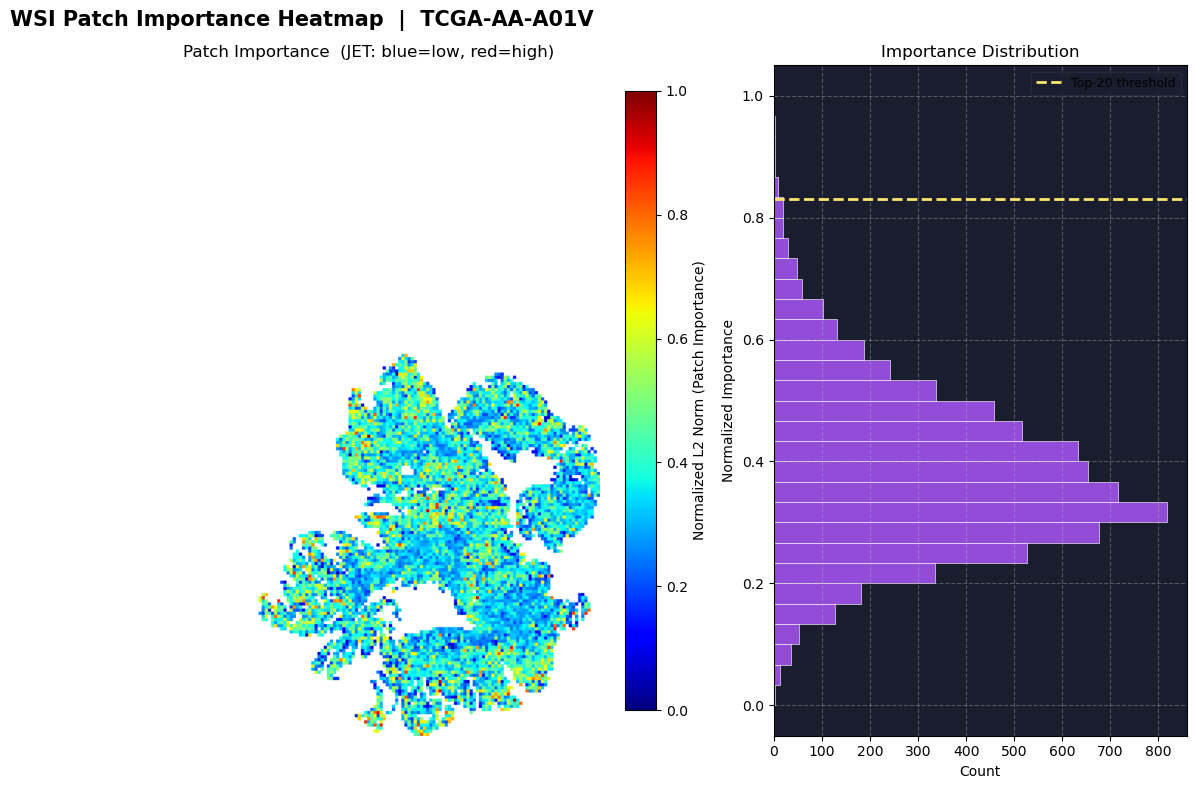

✅ 已保存: wsi_heatmap_rf.png
   Top-5 坐标: [[ 37981  60955]
 [ 47709  73243]
 [ 55901  87579]
 [ 49757 101403]
 [ 62045 104475]]


In [30]:
# ============================================================
# %% [8] WSI 热图重建（JET 配色 + 无缝拼接）
# ============================================================
def rebuild_wsi_heatmap_rf(patient_id, pt_file_path, save_path, dark_theme=True):
    data   = torch.load(pt_file_path)
    feats  = data['feats']
    coords = data['coords']

    if len(coords) == 0 or coords.shape[0] == 0:
        print(f"⚠️ {patient_id} 的 coords 为空，请先运行 fix_coords()，跳过。")
        return

    norms      = np.linalg.norm(feats, axis=1)
    A_norm     = (norms - norms.min()) / (norms.max() - norms.min() + 1e-8)

    scale      = 0.08
    patch_size = 512
    max_x, max_y = np.max(coords, axis=0)
    canvas_h   = int((max_y + patch_size) * scale) + 2
    canvas_w   = int((max_x + patch_size) * scale) + 2

    bg_color = (15, 17, 23) if dark_theme else (255, 255, 255)
    canvas   = np.full((canvas_h, canvas_w, 3), bg_color, dtype=np.uint8)

    print(f"重建 {patient_id} ({canvas_w}×{canvas_h})，共 {len(coords)} 个 Patch...")

    # 按重要性从低到高绘制，高重要性压在最上层
    for i in np.argsort(A_norm):
        x, y      = coords[i]
        color_val = int(A_norm[i] * 255)
        color     = cv2.applyColorMap(
            np.array([[color_val]], dtype=np.uint8), cv2.COLORMAP_JET   # 经典 JET 配色
        )[0][0].tolist()

        x0 = int(x * scale)
        y0 = int(y * scale)
        x1 = int((x + patch_size) * scale) + 1   # +1 消除缝隙
        y1 = int((y + patch_size) * scale) + 1
        cv2.rectangle(canvas, (x0, y0), (x1, y1), color, -1)

    # Top-20 加白色边框高亮
    for i in np.argsort(A_norm)[-20:]:
        x, y = coords[i]
        cv2.rectangle(canvas,
                      (int(x * scale), int(y * scale)),
                      (int((x + patch_size) * scale) + 1, int((y + patch_size) * scale) + 1),
                      (255, 255, 255), 1)

    cv2.imwrite(save_path, canvas)

    bg, tc = ('#0F1117', 'white') if dark_theme else ('white', 'black')
    fig, axes = plt.subplots(1, 2, figsize=(18, 8), facecolor=bg,
                              gridspec_kw={'width_ratios': [3, 1]})
    fig.suptitle(f'WSI Patch Importance Heatmap  |  {patient_id}',
                 fontsize=15, color=tc, fontweight='bold')

    axes[0].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Patch Importance  (JET: blue=low, red=high)',
                      color=tc, fontsize=12)
    axes[0].axis('off')
    axes[0].set_facecolor(bg)

    sm   = plt.cm.ScalarMappable(cmap='jet', norm=Normalize(vmin=0, vmax=1))  # JET 颜色条
    cbar = fig.colorbar(sm, ax=axes[0], fraction=0.025, pad=0.02)
    cbar.set_label('Normalized L2 Norm (Patch Importance)', color=tc, fontsize=10)
    cbar.ax.yaxis.set_tick_params(color=tc)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color=tc)

    axes[1].hist(A_norm, bins=30, color='#A855F7', edgecolor='white',
                 linewidth=0.5, orientation='horizontal', alpha=0.85)
    axes[1].axhline(A_norm[np.argsort(A_norm)[-20]], color='#FFE66D',
                    linestyle='--', lw=2, label='Top-20 threshold')
    axes[1].set_title('Importance Distribution', color=tc, fontsize=12)
    axes[1].set_xlabel('Count', color=tc)
    axes[1].set_ylabel('Normalized Importance', color=tc)
    axes[1].tick_params(colors=tc)
    axes[1].set_facecolor('#1A1D2E')
    axes[1].legend(fontsize=9, facecolor='#1A1D2E', edgecolor='#2A2D3E', labelcolor=tc)
    axes[1].grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(save_path.replace('.png', '_display.png'),
                dpi=150, bbox_inches='tight', facecolor=bg)
    plt.show()
    print(f"✅ 已保存: {save_path}")
    print(f"   Top-5 坐标: {coords[np.argsort(A_norm)[-5:][::-1]]}")


# 单个病人调用示例
rebuild_wsi_heatmap_rf(
    patient_id   = "TCGA-AA-A01V",
    pt_file_path = r"G:\WSLearning\Data\features.vit\val\High\TCGA-AA-A01V.pt",
    save_path    = "wsi_heatmap_rf.png",
    dark_theme   = False
)

# 批量处理
# for pt_file in Path(FEATURE_ROOT + r"\val").rglob("*.pt"):
#     label = "High" if "High" in str(pt_file) else "Low"
#     rebuild_wsi_heatmap_rf(
#         patient_id   = f"[{label}] {pt_file.stem}",
#         pt_file_path = str(pt_file),
#         save_path    = f"wsi_{pt_file.stem}.png",
#         dark_theme   = True
#     )
#G:\WSLearning\Data\features.vit\val\High\TCGA-AA-A01V.pt